# So sánh BraTS 2020 và BraTS-Africa

Notebook đọc bảng thống kê theo bệnh nhân để so sánh thể tích WT, cường độ MRI,
tỉ lệ lát có u và tỉ lệ voxel WT trong não, sau đó giảm chiều bằng PCA.
BraTS 2020 có 369 ca, Africa được giữ riêng thành 95 glioma và 51 u khác.

Chạy lần lượt các ô bằng runtime CPU, không cần tải lại MRI hoặc NPZ.
Bảng BraTS 2020 và split được đóng kèm bộ mã từ repo, bảng Africa lấy từ Kaggle phiên bản 1.
Các bảng này đã được tính trên NIfTI đầu vào, trước bước z-score chung.


## 1. Chuẩn bị mã nguồn

Chọn `brats_africa_compare.zip` khi Colab yêu cầu. Bộ mã có bảng EDA BraTS 2020 và split cố định.
Phần so sánh và PCA nằm trong `src/preprocess/compare_africa.py`, notebook gọi từng bước và hiển thị kết quả.


In [1]:
# 1. Mở bộ mã và chuyển về thư mục làm việc.
import os
import sys
import json
import subprocess
import zipfile
from pathlib import Path

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

required_modules = [
    'src/preprocess/compare_africa.py',
    'configs/compare_inputs.json'
]
candidates = [Path.cwd(), Path.cwd().parent, Path('/content/brats-africa-compare-workspace')]
REPO_DIR = next(
    (path for path in candidates if all((path / name).is_file() for name in required_modules)),
    None
)

if REPO_DIR is None and IN_COLAB:
    from google.colab import files
    uploaded = files.upload()
    assert 'brats_africa_compare.zip' in uploaded, 'Chọn đúng bộ mã brats_africa_compare.zip mới.'
    REPO_DIR = Path('/content/brats-africa-compare-workspace')
    REPO_DIR.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile('brats_africa_compare.zip') as archive:
        for member in archive.infolist():
            target = (REPO_DIR / member.filename).resolve()
            assert target.is_relative_to(REPO_DIR.resolve()), 'Đường dẫn trong ZIP không hợp lệ.'
        archive.extractall(REPO_DIR)
    del uploaded

assert REPO_DIR is not None, 'Cần mở notebook từ bộ mã đã giải nén.'
assert all((REPO_DIR / name).is_file() for name in required_modules), 'Cần tải lại ZIP bộ mã mới.'
REPO_DIR = REPO_DIR.resolve()
os.chdir(REPO_DIR)
os.environ['MPLCONFIGDIR'] = str(REPO_DIR / '.mplconfig')
print('Thư mục làm việc:', REPO_DIR)

Saving brats_africa_compare.zip to brats_africa_compare.zip
Thư mục làm việc: /content/brats-africa-compare-workspace


## 2. Cài thư viện

Dùng pandas để đọc bảng, matplotlib để vẽ và scikit-learn để chuẩn hóa đặc trưng, tính PCA.
Nếu Colab yêu cầu khởi động lại runtime, thực hiện rồi chạy lại từ ô 1.


In [2]:
# 2. Cài thư viện và tạo hàm gọi các module của dự án.
subprocess.run(
    [sys.executable, '-m', 'pip', 'install', '-q', '-r', 'requirements-compare.txt'],
    check=True
)

def run_module(module, *args):
    subprocess.run(
        [sys.executable, '-m', module, *map(str, args)],
        check=True,
        cwd=REPO_DIR
    )

## 3. Cấu hình dữ liệu và thư mục kết quả

Kết quả lưu trên Drive với tên `africa_compare_run01`. Khi làm một thử nghiệm mới, đổi thành run02.
Các bảng đầu vào được kiểm tra SHA256 để tránh vô tình ghép khác phiên bản dữ liệu.
Chạy lại cùng run01 sẽ ghi đè các kết quả cùng tên trong thư mục đó.


In [3]:
# 3. Kết nối Drive và đặt đường dẫn dùng chung.
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    INPUT_DIR = Path('/content/brats-africa-compare-inputs')
    OUT_DIR = Path('/content/drive/MyDrive/brats_africa_midterm/africa_compare_run01')
else:
    INPUT_DIR = REPO_DIR / 'data/africa_compare_inputs'
    OUT_DIR = REPO_DIR / 'results/africa/africa_compare_run01'

DATASET = 'trinhthuhuyenhuyen/brats-africa-preprocessed-224-v11/1'
BRATS2020_CSV = REPO_DIR / 'results/eda_brats2020_cases.csv'
SPLITS_FILE = REPO_DIR / 'configs/splits.json'
AFRICA_CSV = INPUT_DIR / 'eda_africa_cases.csv'
INPUT_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)
print('Bảng BraTS 2020:', BRATS2020_CSV)
print('Bảng Africa:', AFRICA_CSV)
print('Kết quả:', OUT_DIR)

Mounted at /content/drive
Bảng BraTS 2020: /content/brats-africa-compare-workspace/results/eda_brats2020_cases.csv
Bảng Africa: /content/brats-africa-compare-inputs/eda_africa_cases.csv
Kết quả: /content/drive/MyDrive/brats_africa_midterm/africa_compare_run01


## 4. Cấu hình Kaggle API

Chọn `kaggle.json` của tài khoản có quyền xem dataset Africa.
Nếu đã cấu hình trong runtime thì dùng lại, không cần upload thêm.
Không đưa file xác thực vào Git hoặc ZIP kết quả.


In [4]:
# 4. Lưu thông tin xác thực vào thư mục cấu hình Kaggle.
credentials = Path.home() / '.kaggle' / 'kaggle.json'

if not credentials.is_file():
    assert IN_COLAB, 'Cần cấu hình kaggle.json trước khi chạy trên máy cá nhân.'
    from google.colab import files
    uploaded = files.upload()
    assert 'kaggle.json' in uploaded, 'Chọn đúng file kaggle.json.'
    credentials.parent.mkdir(parents=True, exist_ok=True)
    credentials.write_bytes(uploaded['kaggle.json'])
    credentials.chmod(0o600)
    Path('kaggle.json').unlink(missing_ok=True)
    del uploaded

os.environ['KAGGLE_CONFIG_DIR'] = str(credentials.parent)
print('Đã cấu hình Kaggle API.')

Saving kaggle.json to kaggle.json
Đã cấu hình Kaggle API.


## 5. Lấy bảng thống kê Africa và đối chiếu đầu vào

Chỉ tải `eda_africa_cases.csv`, không tải toàn bộ dataset 2,45 GiB.
Nếu bảng từ notebook B_africa_data còn trong runtime và checksum khớp thì dùng lại.
Checksum và nguồn của ba đầu vào được ghi trong `configs/compare_inputs.json`.
Nếu gặp lỗi 403, kiểm tra quyền xem dataset của tài khoản Kaggle.


In [5]:
# 5. Lấy bảng EDA và kiểm tra đúng phiên bản đã chốt.
import hashlib
import shutil

input_info = json.loads((REPO_DIR / 'configs/compare_inputs.json').read_text(encoding='utf-8'))

def file_hash(path):
    return hashlib.sha256(path.read_bytes().replace(b'\r\n', b'\n')).hexdigest()

cached_africa = Path('/content/brats_africa_preprocessed_224_v11/eda_africa_cases.csv')
expected_africa = input_info['sha256']['eda_africa_cases.csv']
if AFRICA_CSV.is_file() and file_hash(AFRICA_CSV) == expected_africa:
    print('Dùng lại bảng Africa đã có.')
elif cached_africa.is_file() and file_hash(cached_africa) == expected_africa:
    shutil.copy2(cached_africa, AFRICA_CSV)
    print('Dùng bảng Africa từ lần chạy B_africa_data.')
else:
    from kaggle.api.kaggle_api_extended import KaggleApi
    api = KaggleApi()
    api.authenticate()
    api.dataset_download_file(
        DATASET, 'eda_africa_cases.csv', path=str(INPUT_DIR),
        force=True, quiet=False, unzip=True
    )

for name, path in [
    ('eda_brats2020_cases.csv', BRATS2020_CSV),
    ('eda_africa_cases.csv', AFRICA_CSV),
    ('splits.json', SPLITS_FILE)
]:
    assert file_hash(path) == input_info['sha256'][name], f'Không khớp checksum: {name}'
    print('Đã kiểm tra:', name)

# Giữ bản CSV và split đã sử dụng để đối chiếu kết quả về sau.
source_dir = OUT_DIR / 'inputs'
source_dir.mkdir(exist_ok=True)
for path in [BRATS2020_CSV, AFRICA_CSV, SPLITS_FILE]:
    shutil.copy2(path, source_dir / path.name)
shutil.copy2(REPO_DIR / 'configs/compare_inputs.json', source_dir / 'compare_inputs.json')


Dataset URL: https://www.kaggle.com/datasets/trinhthuhuyenhuyen/brats-africa-preprocessed-224-v11/versions/1


100%|██████████| 78.5k/78.5k [00:00<00:00, 2.60MB/s]


Đã kiểm tra: eda_brats2020_cases.csv
Đã kiểm tra: eda_africa_cases.csv
Đã kiểm tra: splits.json


PosixPath('/content/drive/MyDrive/brats_africa_midterm/africa_compare_run01/inputs/compare_inputs.json')

## 6. Kiểm tra và ghép đặc trưng theo bệnh nhân

Đối chiếu đủ 369 ID BraTS 2020 với split 259 train, 55 val, 55 test.
Kiểm tra ID không trùng, đủ 95 glioma và 51 u khác, các đặc trưng không có NaN hoặc Inf.
Tập Africa được ghi là dữ liệu ngoài nguồn, không thêm vào train hay validation.

Bảng tổng hợp dùng SD mẫu theo bệnh nhân. Tỉ lệ lát có u và voxel WT tính gộp trong từng nhóm.
Thể tích tính từ voxel NIfTI gốc và spacing mm, đơn vị mL tương đương cm³.


In [6]:
# 6. Ghép hai bảng EDA và xuất bảng so sánh ba nhóm.
compare_args = [
    '--brats2020-csv', str(BRATS2020_CSV),
    '--africa-csv', str(AFRICA_CSV),
    '--splits', str(SPLITS_FILE),
    '--out-dir', str(OUT_DIR)
]
run_module('src.preprocess.compare_africa', *compare_args, '--stage', 'prepare')

import pandas as pd
from IPython.display import display, Image

features = pd.read_csv(OUT_DIR / 'combined_case_features.csv')
comparison = pd.read_csv(OUT_DIR / 'cohort_comparison.csv')
assert len(features) == 515 and features['case_id'].is_unique
display(comparison.round(2))
display(features.groupby(['cohort', 'split']).size().rename('num_cases').to_frame())


,cohort,num_cases,wt_mean_ml,wt_sd_ml,wt_median_ml,wt_min_ml,wt_max_ml,tumor_slice_pct,wt_voxel_pct_in_brain
0,BraTS 2020,369,99.55,59.43,90.74,7.28,361.78,42.70,6.87
1,Africa glioma,95,161.58,93.66,162.87,1.03,408.50,47.93,10.49
2,Africa other tumors,51,124.67,98.45,82.80,10.77,412.29,47.01,7.92


num_cases
cohort              split                          
Africa glioma       external_descriptive         95
Africa other tumors external_descriptive         51
BraTS 2020          test                         55
                    train                       259
                    val                          55

## 7. Vẽ biểu đồ so sánh phân bố

Vẽ thể tích WT, cường độ trung bình bốn MRI và mức mất cân bằng lớp.
Các boxplot biểu diễn phân bố theo bệnh nhân, các điểm bên ngoài râu được giữ lại.
Cường độ là thống kê NIfTI đầu vào trước z-score chung, nguồn dữ liệu đã có các bước xử lý của challenge.
Khác biệt ở biểu đồ chưa đủ để xác định nguyên nhân lâm sàng hoặc chất lượng máy chụp.


africa_01_wt_volume_comparison.png


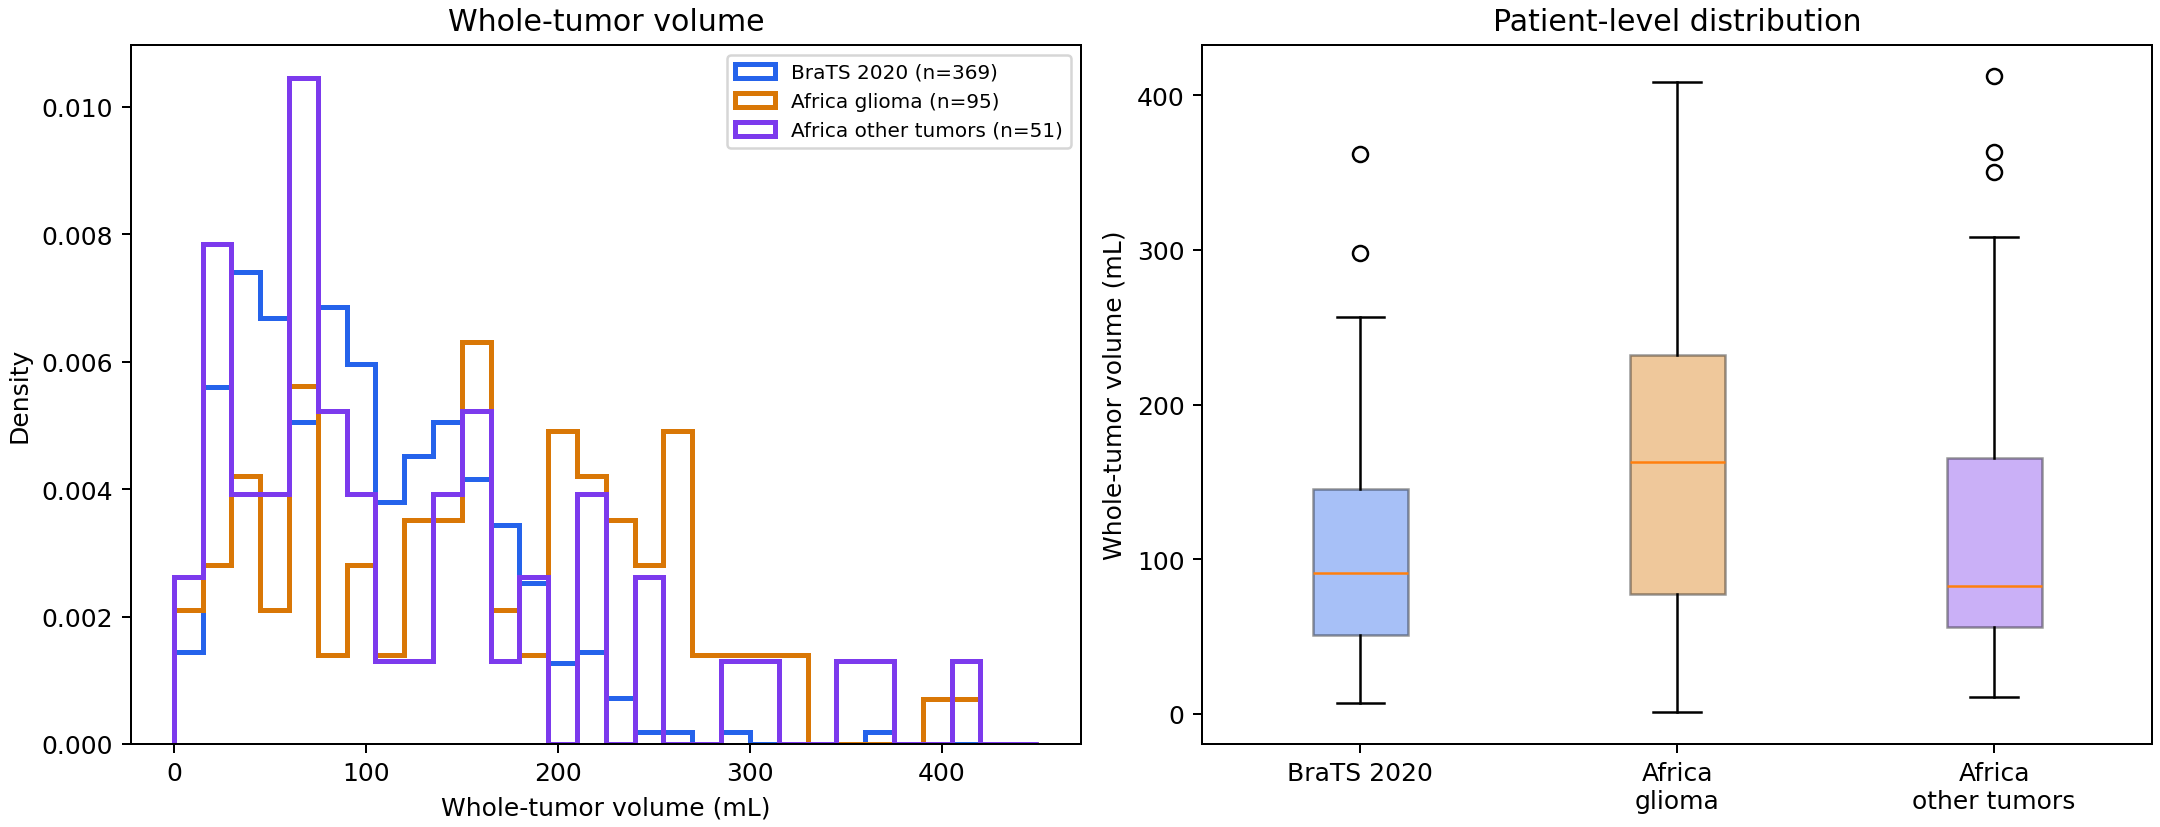

africa_02_intensity_comparison.png


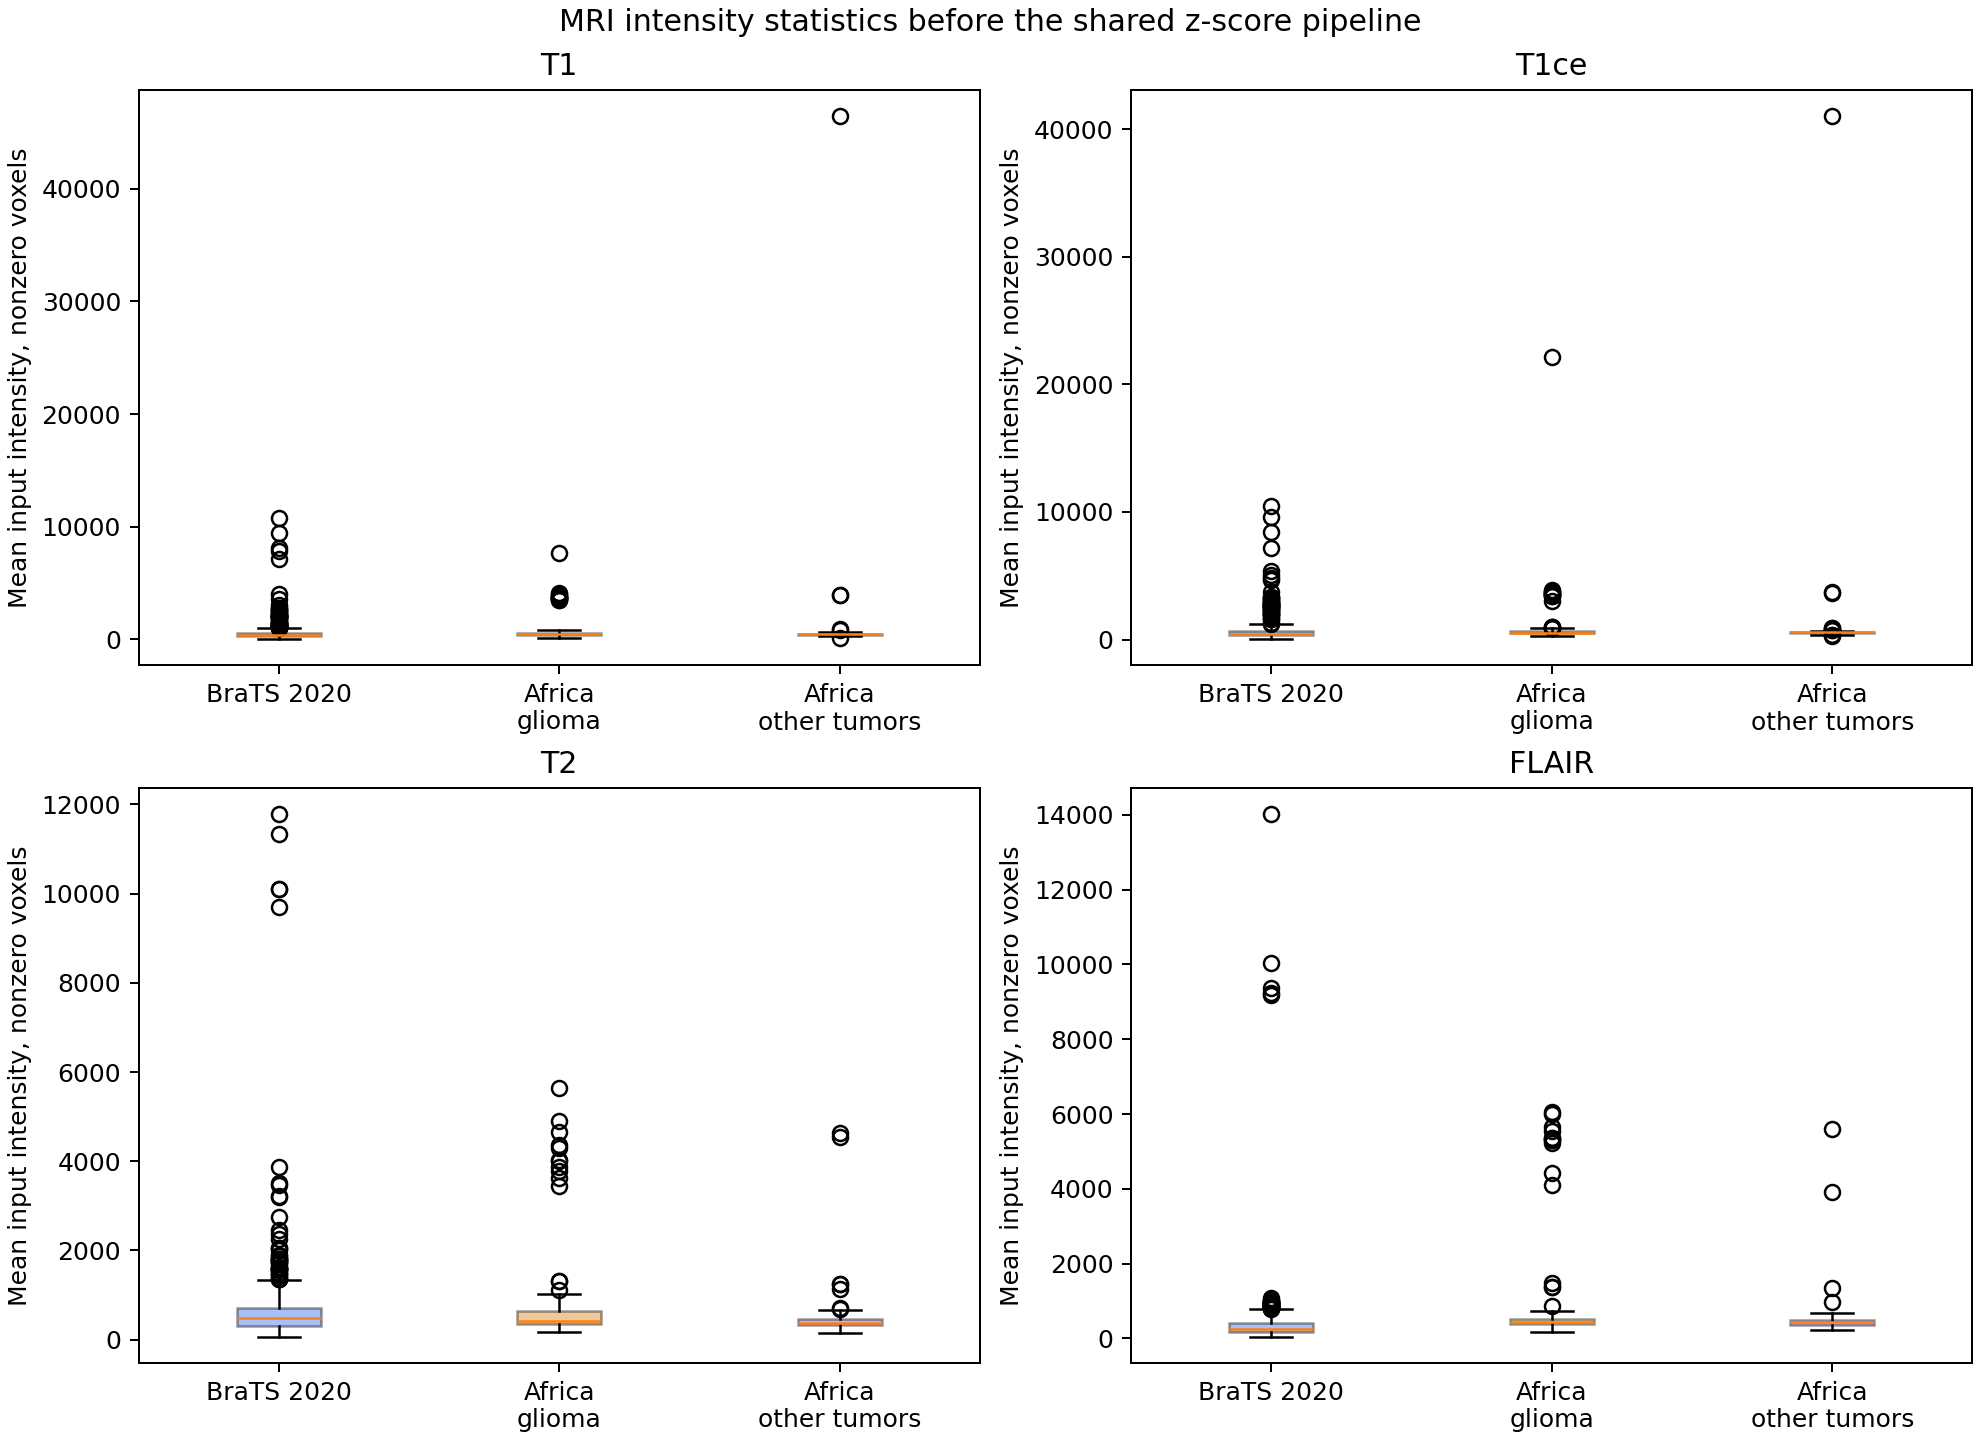

africa_03_class_imbalance_comparison.png


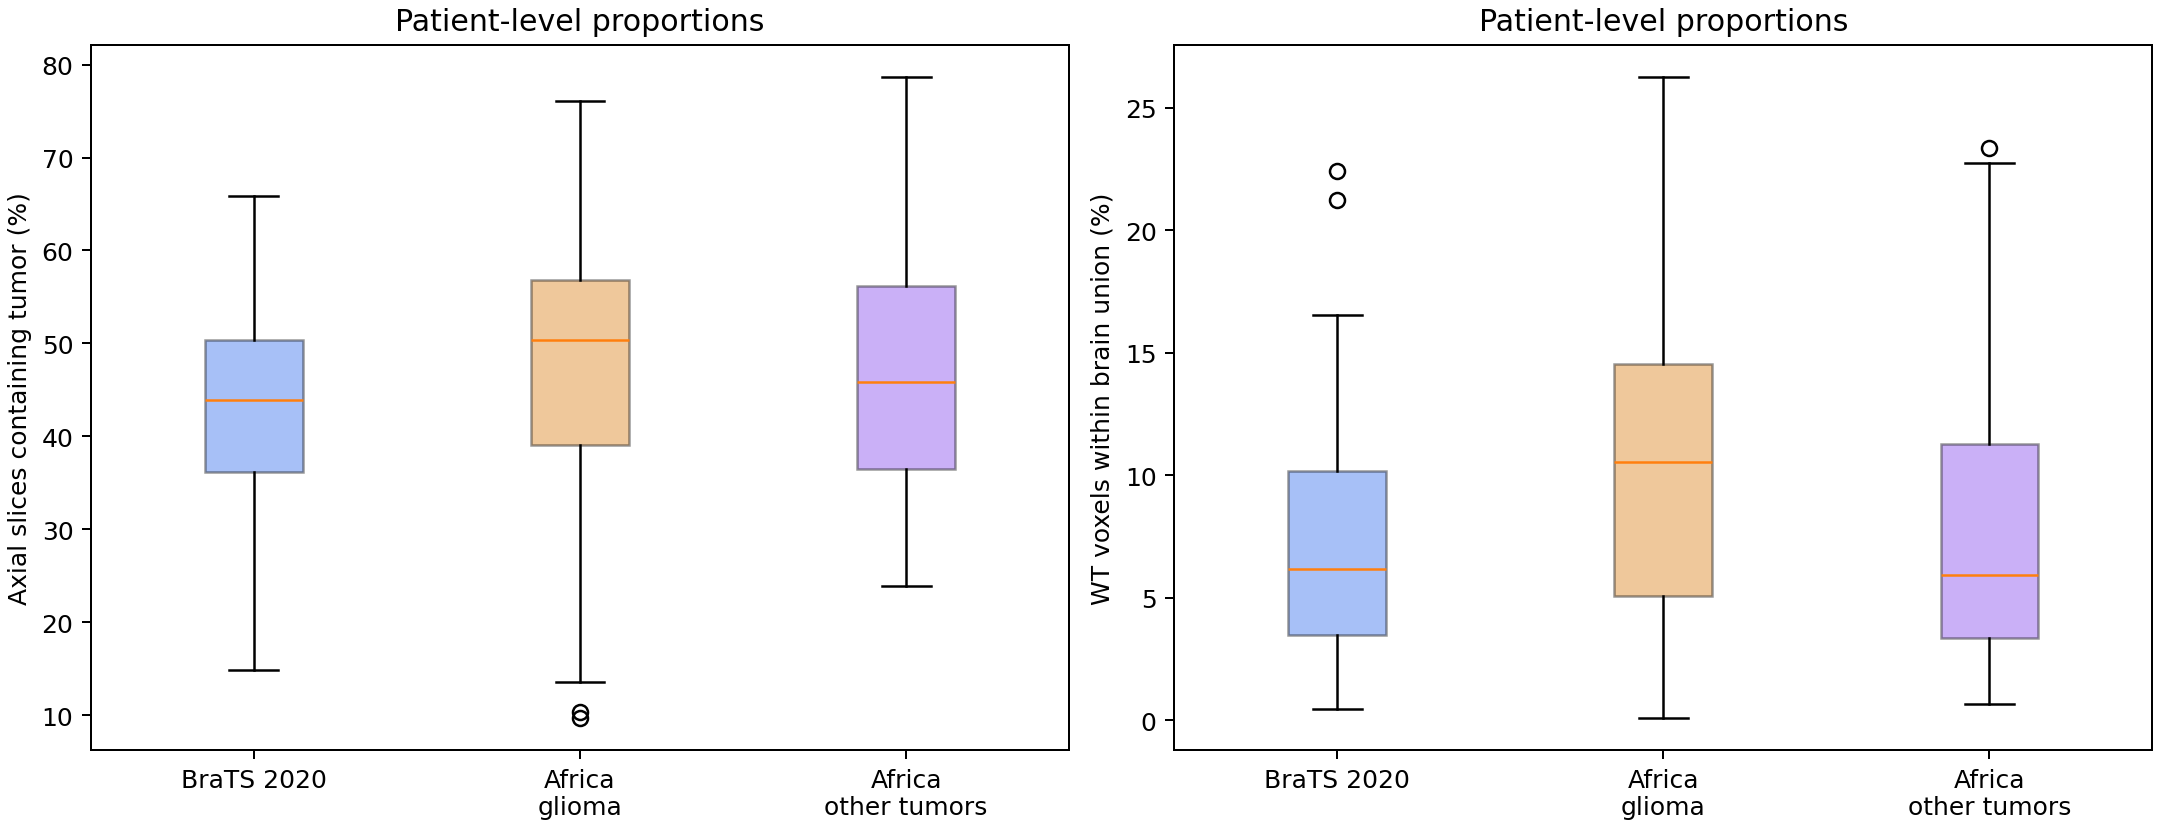

In [7]:
# 7. Vẽ và xem ba biểu đồ phân bố.
run_module('src.preprocess.compare_africa', *compare_args, '--stage', 'plots')

for name in [
    'africa_01_wt_volume_comparison.png',
    'africa_02_intensity_comparison.png',
    'africa_03_class_imbalance_comparison.png'
]:
    print(name)
    display(Image(filename=str(OUT_DIR / 'figures' / name), width=1100))

## 8. Chuẩn hóa đặc trưng và giảm chiều bằng PCA

PCA chính dùng 21 đặc trưng: mean, std, p05, p50, p95 của mỗi MRI và thể tích não.
Không đưa thể tích WT vào PCA chính. Scaler và PCA chỉ fit trên 259 ca train BraTS 2020,
sau đó chiếu toàn bộ 515 ca vào hai thành phần PC1, PC2.

PCA bổ sung có thêm thể tích WT gốc, được ghi riêng vì sử dụng thông tin ground truth.
Mỗi hình có khung toàn bộ ca và khung phóng to theo phân vị 1–99%, mọi ca vẫn giữ trong phép tính và CSV.
Tỉ lệ phương sai trên trục được tính trên tập train dùng để fit, không phải trên toàn bộ 515 ca.


PCA: mri


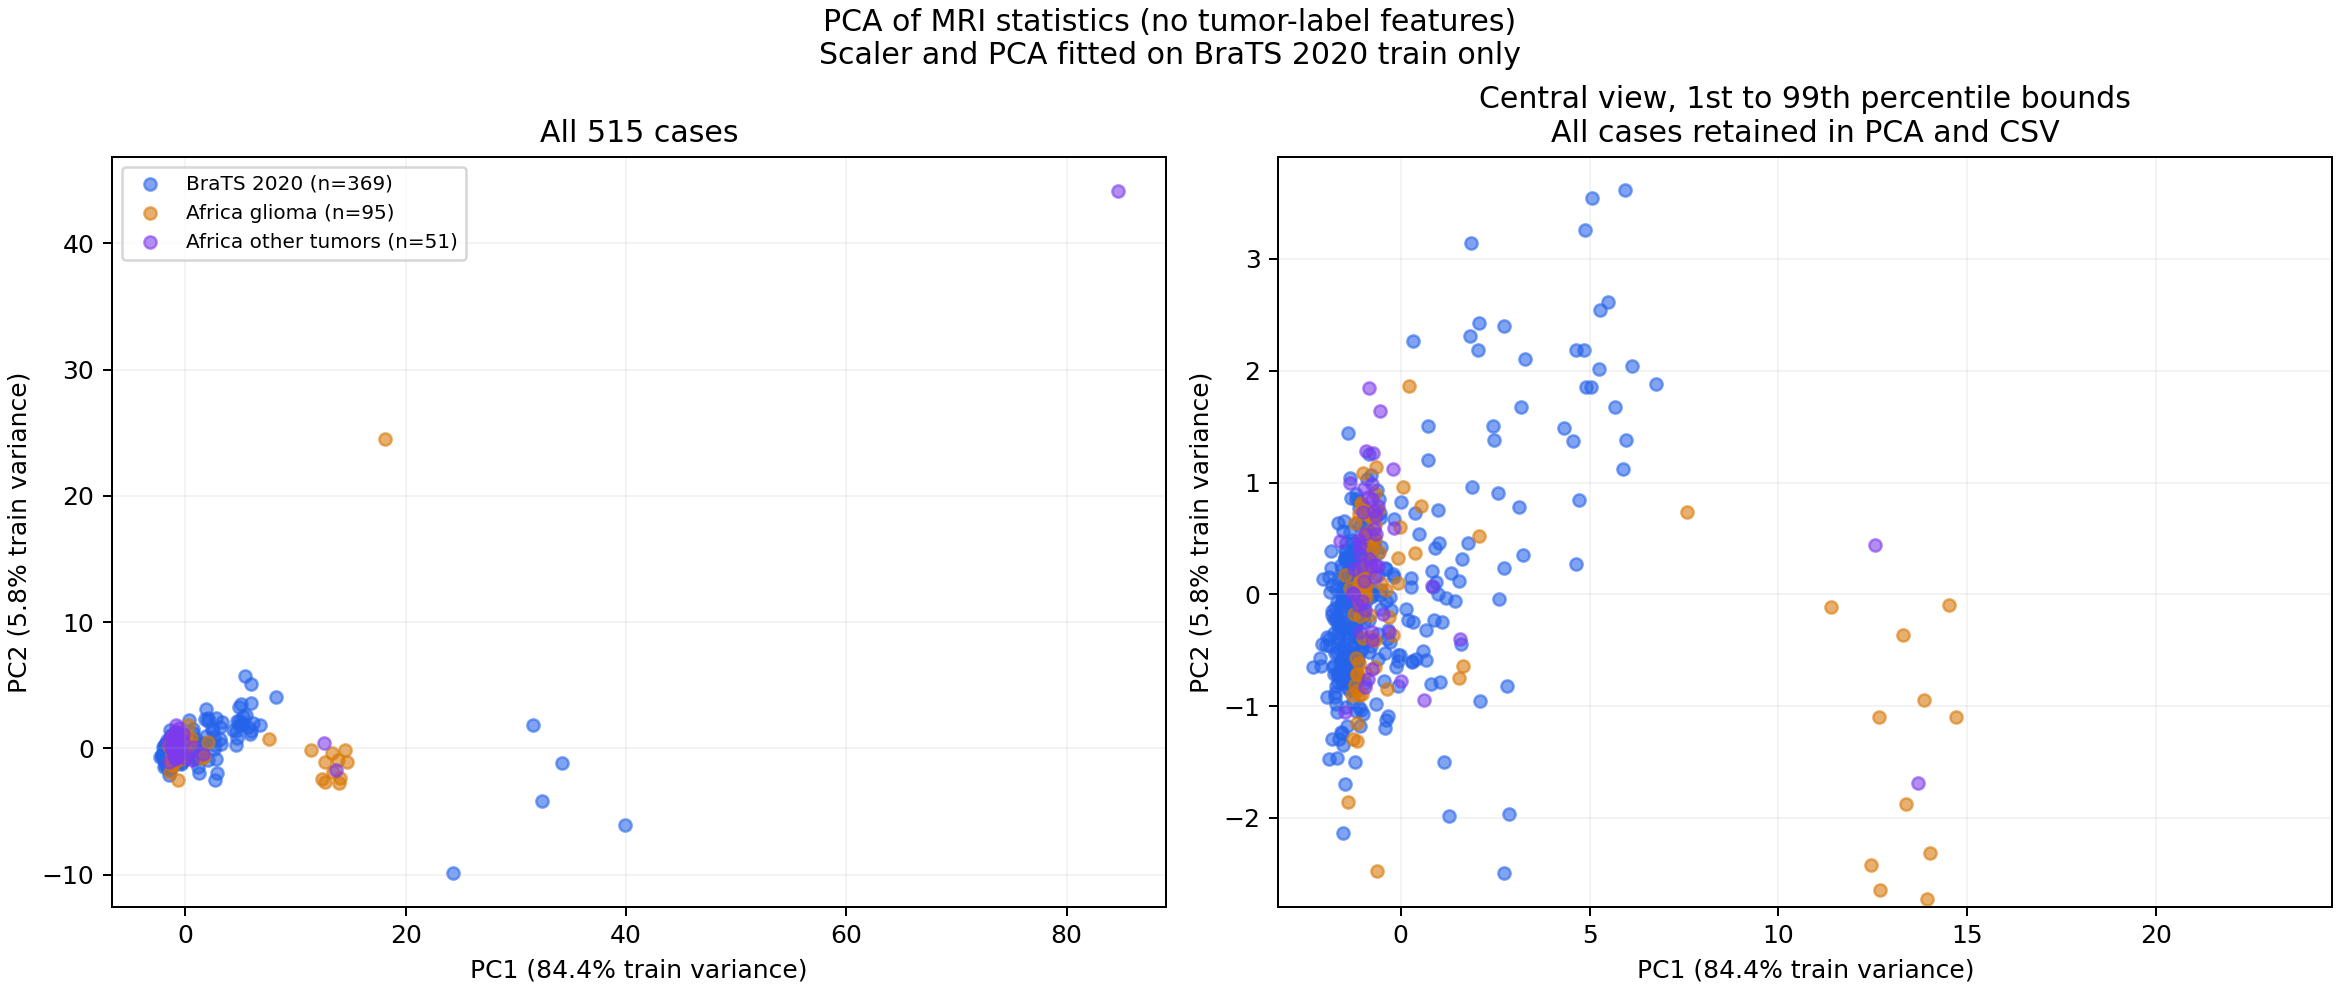

PCA: with_wt


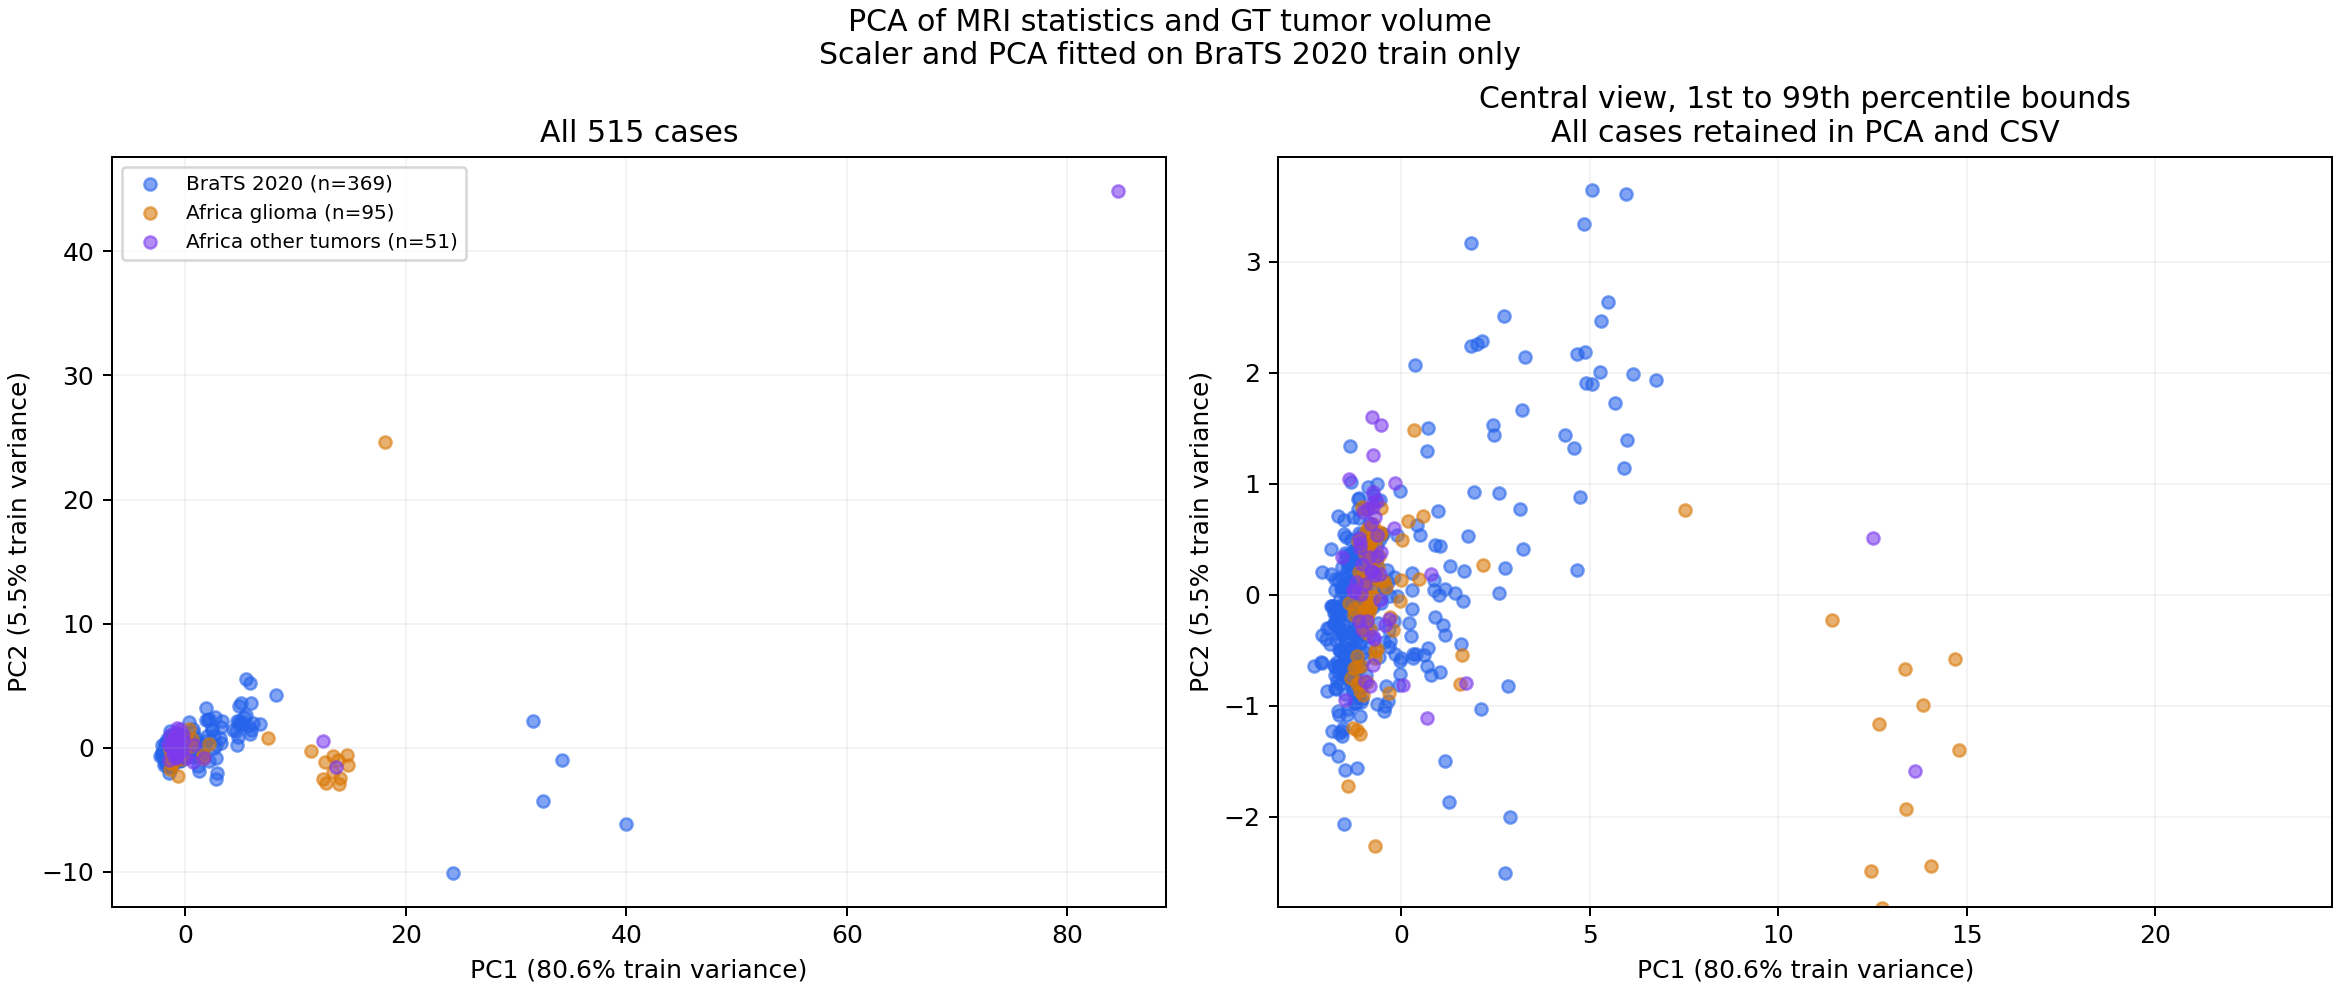

In [8]:
# 8. Chạy hai PCA và xem hình chiếu 2D.
run_module('src.preprocess.compare_africa', *compare_args, '--stage', 'pca')

for suffix in ['mri', 'with_wt']:
    print('PCA:', suffix)
    display(Image(
        filename=str(OUT_DIR / 'figures' / f'africa_04_pca_{suffix}.png'),
        width=1200
    ))

## 9. Kiểm tra PCA và đọc hệ số đặc trưng

Kiểm tra lại đúng các ID train được dùng để fit và số dòng sau khi chiếu.
Bảng hệ số cho biết mỗi đặc trưng đã chuẩn hóa tham gia vào PC1, PC2 như thế nào.
Dấu dương, âm của hệ số cho biết hướng trên trục, không phải mức tốt hay xấu của dữ liệu.
Đọc cả hình toàn bộ và hình phóng to, không loại ca chỉ vì nằm xa cụm chính.
PCA mô tả phân bố, chưa cho biết mô hình phân đoạn tổng quát hóa tốt hay kém trên Africa.


In [9]:
# 9. Kiểm tra tập fit, phương sai giải thích và hệ số PCA chính.
splits = json.loads(SPLITS_FILE.read_text(encoding='utf-8'))['splits']
pca_summary = []
for suffix in ['mri', 'with_wt']:
    metadata = json.loads((OUT_DIR / f'pca_{suffix}_transform.json').read_text(encoding='utf-8'))
    scores = pd.read_csv(OUT_DIR / f'pca_{suffix}_scores.csv')
    assert len(metadata['fit_cases']) == 259
    assert set(metadata['fit_cases']) == set(splits['train'])
    assert len(scores) == 515 and scores['case_id'].is_unique
    ratio = metadata['explained_variance_ratio']
    pca_summary.append({
        'pca': suffix,
        'num_features': metadata['num_features'],
        'fit_cases': len(metadata['fit_cases']),
        'PC1_pct': 100 * ratio[0],
        'PC2_pct': 100 * ratio[1],
        'PC1_PC2_pct': 100 * sum(ratio),
        'uses_gt_volume': metadata['uses_ground_truth_volume']
    })

pca_summary = pd.DataFrame(pca_summary)
pca_summary.to_csv(OUT_DIR / 'pca_summary.csv', index=False)
display(pca_summary.round(2))

loadings = pd.read_csv(OUT_DIR / 'pca_mri_loadings.csv')
for component in ['PC1', 'PC2']:
    print('Các hệ số có trị tuyệt đối lớn nhất trên', component)
    top = loadings[component].abs().sort_values(ascending=False).head(8).index
    display(loadings.loc[top, ['feature', component]])

,pca,num_features,fit_cases,PC1_pct,PC2_pct,PC1_PC2_pct,uses_gt_volume
0,mri,21,259,84.40,5.79,90.20,False
1,with_wt,22,259,80.64,5.54,86.18,True


Các hệ số có trị tuyệt đối lớn nhất trên PC1


,feature,PC1
3,t1_p50_brain,0.232140
0,t1_mean_brain,0.231929
4,t1_p95_brain,0.231056
13,t2_p50_brain,0.230413
10,t2_mean_brain,0.230103
14,t2_p95_brain,0.228949
17,flair_p05_brain,0.227686
1,t1_std_brain,0.227350


Các hệ số có trị tuyệt đối lớn nhất trên PC2


,feature,PC2
20,brain_volume_ml,0.552493
7,t1ce_p05_brain,0.325720
5,t1ce_mean_brain,0.287191
9,t1ce_p95_brain,0.284009
8,t1ce_p50_brain,0.281181
16,flair_std_brain,-0.263075
19,flair_p95_brain,-0.252255
6,t1ce_std_brain,0.246647


## 10. Lưu và tải kết quả

ZIP chứa bảng đầu vào, bảng ghép đặc trưng, so sánh, PCA scores, hệ số và các hình.
Kết quả cũng đã lưu trên Drive. Không đưa kaggle.json vào repo hoặc ZIP kết quả.
Sau khi chạy xong, chọn File → Save a copy in Drive để giữ notebook cùng output.
Khi viết báo cáo, dùng PCA MRI làm kết quả chính và nêu riêng PCA có thể tích WT là phân tích bổ sung.


In [10]:
# 10. Nén toàn bộ kết quả của lần chạy này và tải về máy.
notes = [
    'SO SÁNH BRATS 2020 VÀ BRATS-AFRICA',
    '369 ca BraTS 2020, 95 Africa glioma, 51 Africa u khác.',
    'Thống kê lấy từ NIfTI đầu vào, trước z-score chung.',
    'PCA chính dùng 21 đặc trưng gồm thống kê MRI và thể tích não, không dùng thể tích WT.',
    'Scaler và PCA chỉ fit trên 259 ca train BraTS 2020.',
    'PCA with_wt là phân tích bổ sung có thông tin ground truth.',
    'Hình phóng to chỉ thay đổi giới hạn hiển thị, CSV vẫn giữ đủ 515 ca.',
    'PCA không phải kết quả đánh giá mô hình trên Africa.'
]
(OUT_DIR / 'README_RESULTS.txt').write_text('\n'.join(notes) + '\n', encoding='utf-8')
archive_path = shutil.make_archive(str(OUT_DIR), 'zip', OUT_DIR)
print('ZIP kết quả:', archive_path)
if IN_COLAB:
    from google.colab import files
    files.download(archive_path)

ZIP kết quả: /content/drive/MyDrive/brats_africa_midterm/africa_compare_run01.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>